# Smart Water Quality Monitoring System
### Unified Dataset Exploration & Leakage-Safe Preprocessing Notebook

**Research scope:** Kaggle *Water Quality and Potability* — reproducible EDA, figures and preprocessing through train/test-ready data. **No classifier is trained in this notebook**; the output is not a drinking-water safety assessment.

**Contributions consolidated:** Moamen — initial EDA, missingness and class balance; Mohamed Ali (Abu Ali) — distributions, boxplots, correlation and sensor mapping; Youssef — stratified split, median imputation and StandardScaler; Bakr — integration, validation, figure export and documentation.

**Reproducibility:** Place this notebook beside `water_potability.csv`, then run **Kernel → Restart & Run All**. Outputs are written to `figures/` and `outputs/`. The notebook also accepts a `data/water_potability.csv` layout.

**Safety note:** `Potability` is a dataset label. An ML prediction trained on these data would not certify that a real sample is safe to drink. A four-sensor kit cannot directly provide all nine model inputs.

## 0. Imports, fixed configuration and file paths

Use deterministic train/test sampling (`random_state=42`). Exploratory plots are derived from the **raw** dataset for descriptive analysis only; all learned imputation and scaling statistics must be fitted on training data after splitting. No artificial training/test look-ahead is permitted.

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy.stats import gaussian_kde
from IPython.display import display

from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
TEST_SIZE = 0.20
FEATURES = [
    'ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate',
    'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity'
]
TARGET = 'Potability'
CLASS_NAMES = {0: 'Not potable (0)', 1: 'Potable (1)'}

FIGURES_DIR = Path('figures')
INDIVIDUAL_DIR = FIGURES_DIR / 'individual'
OUTPUTS_DIR = Path('outputs')
for directory in [FIGURES_DIR, INDIVIDUAL_DIR, OUTPUTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

candidates = [Path('water_potability.csv'), Path('data/water_potability.csv'), Path('../water_potability.csv'), Path('../data/water_potability.csv')]
DATA_PATH = next((p for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError('water_potability.csv not found. Run from the supplied project folder, or put CSV beside the notebook.')
print(f'Dataset path: {DATA_PATH.resolve()}')

Dataset path: /mnt/data/Smart_Water_Quality_Final/water_potability.csv


## 1. Dataset loading and schema validation — Moamen / Youssef

Each row represents one water sample. Nine numerical predictor columns are followed by the binary `Potability` target. We explicitly check expected column names, numeric types, allowed label values and duplicate rows.

In [2]:
raw_df = pd.read_csv(DATA_PATH)
expected = FEATURES + [TARGET]
assert list(raw_df.columns) == expected, f'Unexpected schema: {list(raw_df.columns)}'
assert raw_df[FEATURES].apply(pd.api.types.is_numeric_dtype).all(), 'Features must be numeric.'
assert set(raw_df[TARGET].dropna().unique()) == {0, 1}, 'Potability must contain binary 0/1 labels.'
assert raw_df[TARGET].notna().all(), 'Target must not have missing values.'

duplicate_rows = int(raw_df.duplicated().sum())
print(f'Shape: {raw_df.shape[0]:,} rows × {raw_df.shape[1]} columns')
print(f'Duplicate rows: {duplicate_rows}')
print(f'Complete rows: {int(raw_df.notna().all(axis=1).sum()):,}')
display(raw_df.head(5))
display(pd.DataFrame({'dtype': raw_df.dtypes.astype(str), 'non_null': raw_df.notna().sum()}))

Shape: 3,276 rows × 10 columns
Duplicate rows: 0
Complete rows: 2,011


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


,dtype,non_null
ph,float64,2785
Hardness,float64,3276
Solids,float64,3276
Chloramines,float64,3276
Sulfate,float64,2495
Conductivity,float64,3276
Organic_carbon,float64,3276
Trihalomethanes,float64,3114
Turbidity,float64,3276
Potability,int64,3276


## 2. Descriptive statistics — Moamen

The table reports non-null count, mean, median, sample standard deviation, minimum, quartiles and maximum. Missing entries are ignored for each feature's descriptive statistics; this step does not fill missing data.

In [3]:
summary_stats = raw_df[FEATURES].describe().T
summary_stats = summary_stats.rename(columns={'50%':'median', '25%':'Q1', '75%':'Q3'})
summary_stats = summary_stats[['count','mean','median','std','min','Q1','Q3','max']]
print('Summary statistics for the nine features:')
display(summary_stats.round(3))
summary_stats.to_csv(OUTPUTS_DIR/'summary_statistics.csv')

Summary statistics for the nine features:


,count,mean,median,std,min,Q1,Q3,max
ph,2785.0,7.081,7.037,1.594,0.000,6.093,8.062,14.000
Hardness,3276.0,196.369,196.968,32.880,47.432,176.851,216.667,323.124
Solids,3276.0,22014.093,20927.834,8768.571,320.943,15666.690,27332.762,61227.196
Chloramines,3276.0,7.122,7.130,1.583,0.352,6.127,8.115,13.127
Sulfate,2495.0,333.776,333.074,41.417,129.000,307.699,359.950,481.031
Conductivity,3276.0,426.205,421.885,80.824,181.484,365.734,481.792,753.343
Organic_carbon,3276.0,14.285,14.218,3.308,2.200,12.066,16.558,28.300
Trihalomethanes,3114.0,66.396,66.622,16.175,0.738,55.845,77.337,124.000
Turbidity,3276.0,3.967,3.955,0.780,1.450,3.440,4.500,6.739


## 3. Missing-value analysis — Moamen

The missing-value chart is based on the raw CSV. We keep the original number of records; **missing inputs are only imputed after the train/test split**. Counts for different features are not necessarily counts of distinct affected rows.

,missing_count,missing_percent
Sulfate,781,23.84
ph,491,14.99
Trihalomethanes,162,4.95
Hardness,0,0.00
Chloramines,0,0.00
Solids,0,0.00
Conductivity,0,0.00
Organic_carbon,0,0.00
Turbidity,0,0.00
Potability,0,0.00


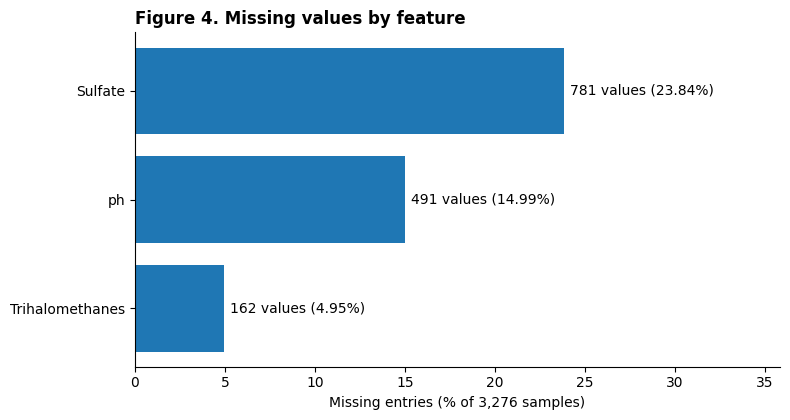

In [4]:
missing_count = raw_df.isna().sum()
missing_pct = (missing_count / len(raw_df) * 100)
missing_table = pd.DataFrame({'missing_count':missing_count, 'missing_percent':missing_pct}).sort_values('missing_count',ascending=False)
display(missing_table.round(2))
missing_table.to_csv(OUTPUTS_DIR/'missing_values.csv')

missing_plot = missing_table.loc[missing_table['missing_count']>0].iloc[::-1]
fig, ax = plt.subplots(figsize=(8,4.3))
bars = ax.barh(missing_plot.index, missing_plot.missing_percent)
for bar, count, percent in zip(bars, missing_plot.missing_count, missing_plot.missing_percent):
    ax.text(bar.get_width()+0.35,bar.get_y()+bar.get_height()/2,
            f'{int(count)} values ({percent:.2f}%)',ha='left',va='center',fontsize=10)
ax.set_xlim(0,max(missing_plot.missing_percent)+12)
ax.set_xlabel('Missing entries (% of 3,276 samples)')
ax.set_title('Figure 4. Missing values by feature',loc='left',fontweight='bold')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR/'figure_04_missing_values.png',dpi=230,bbox_inches='tight')
plt.show()

## 4. Target class balance — Moamen

The binary labels are **dataset annotations**, not an independent drinking-water certification. We examine imbalance so that the split preserves both class frequencies.

,label,count,percent
0,Not potable (0),1998,60.99
1,Potable (1),1278,39.01


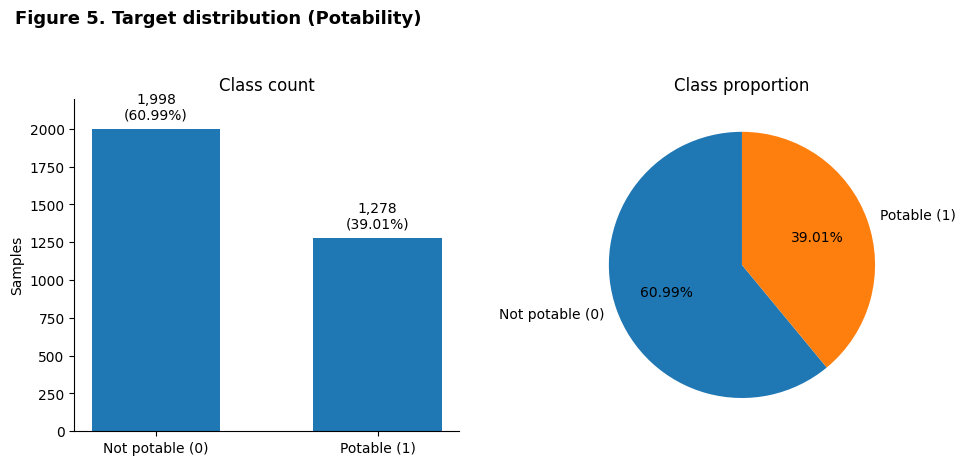

In [5]:
class_counts = raw_df[TARGET].value_counts().reindex([0,1],fill_value=0)
class_pct = class_counts / len(raw_df) * 100
class_table = pd.DataFrame({'label':[CLASS_NAMES[c] for c in class_counts.index], 'count':class_counts.values,'percent':class_pct.values})
display(class_table.round(2))
class_table.to_csv(OUTPUTS_DIR/'target_balance.csv',index=False)

fig,axs=plt.subplots(1,2,figsize=(10,4.7))
ax=axs[0]
bs=ax.bar([CLASS_NAMES[c] for c in class_counts.index],class_counts.values,width=.58)
for b,count,pct in zip(bs,class_counts.values,class_pct.values):
    ax.text(b.get_x()+b.get_width()/2,b.get_height()+45,f'{count:,}\n({pct:.2f}%)',ha='center',va='bottom',fontsize=10)
ax.set_ylim(0,2200);ax.set_ylabel('Samples');ax.set_title('Class count');ax.spines[['top','right']].set_visible(False)
axs[1].pie(class_counts.values,labels=[CLASS_NAMES[c] for c in class_counts.index],autopct='%1.2f%%',startangle=90)
axs[1].set_title('Class proportion')
fig.suptitle('Figure 5. Target distribution (Potability)',x=.02,ha='left',fontweight='bold',fontsize=13)
fig.tight_layout(rect=[0,0,1,.94]);fig.savefig(FIGURES_DIR/'figure_05_target_distribution.png',dpi=230,bbox_inches='tight')
plt.show()

## 5. Univariate distributions — Mohamed Ali (Abu Ali)

Histograms and kernel density estimates (KDE) are shown for all nine raw, non-null feature values. KDE curves are descriptive smoothing, **not formal tests of normality**. `Solids` is visibly right-skewed; most other variables appear more symmetric.

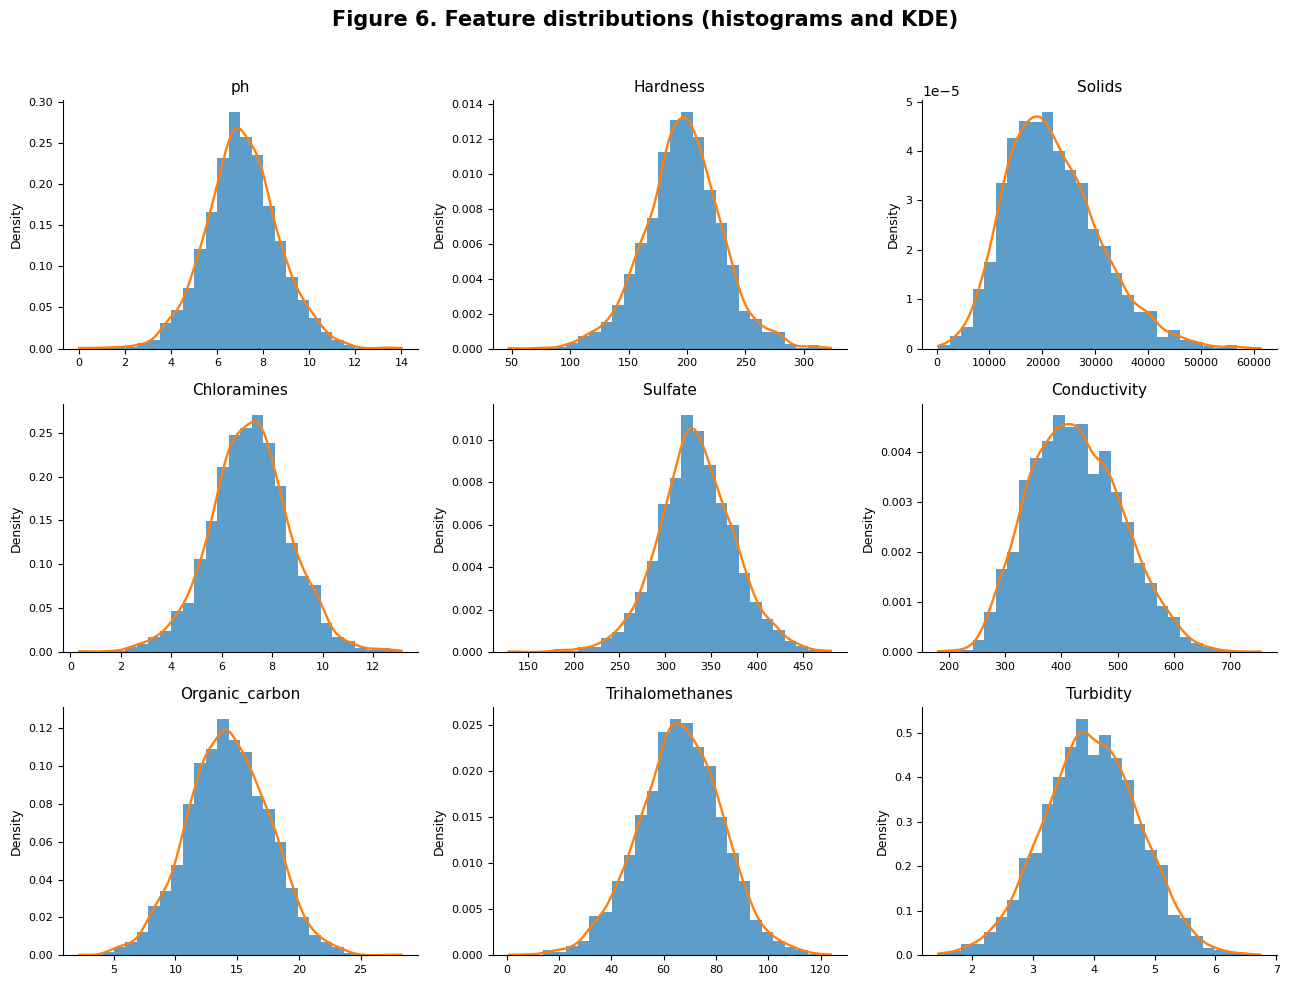

,sample_skewness
ph,0.026
Hardness,-0.039
Solids,0.622
Chloramines,-0.012
Sulfate,-0.036
Conductivity,0.264
Organic_carbon,0.026
Trihalomethanes,-0.083
Turbidity,-0.008


In [6]:
def histogram_kde(ax, values, label, bins=28):
    values = pd.Series(values).dropna().to_numpy(dtype=float)
    ax.hist(values,bins=bins,density=True,alpha=.72)
    if len(values)>5 and np.std(values)>0:
        xs=np.linspace(np.min(values),np.max(values),320)
        ax.plot(xs,gaussian_kde(values)(xs),linewidth=1.7)
    ax.set_title(label,fontsize=11,fontweight='medium')
    ax.set_ylabel('Density',fontsize=9)
    ax.tick_params(axis='both',labelsize=8)
    ax.spines[['top','right']].set_visible(False)

fig,axs=plt.subplots(3,3,figsize=(13,10))
for ax,feature in zip(axs.flat,FEATURES):
    histogram_kde(ax,raw_df[feature],feature)
fig.suptitle('Figure 6. Feature distributions (histograms and KDE)',fontsize=15,fontweight='bold')
fig.tight_layout(rect=[0,0,1,.96]);fig.savefig(FIGURES_DIR/'figure_06_feature_distributions.png',dpi=225,bbox_inches='tight')
plt.show()

# Full-resolution individual plots for inspection and website reuse (not displayed in Notebook).
for feature in FEATURES:
    f,ax=plt.subplots(figsize=(7.4,4.5));histogram_kde(ax,raw_df[feature],feature)
    f.tight_layout();f.savefig(INDIVIDUAL_DIR/f'hist_{feature}.png',dpi=200,bbox_inches='tight');plt.close(f)

skewness=raw_df[FEATURES].skew().rename('sample_skewness').to_frame()
display(skewness.round(3))
skewness.to_csv(OUTPUTS_DIR/'feature_skewness.csv')

## 6. Outliers — Mohamed Ali (Abu Ali)

Standard boxplots display the median, interquartile range and 1.5×IQR whiskers. **Outlier markers are diagnostic, not proof of bad measurements**; we do not silently delete or cap them. Counts are computed per feature on raw non-missing observations.

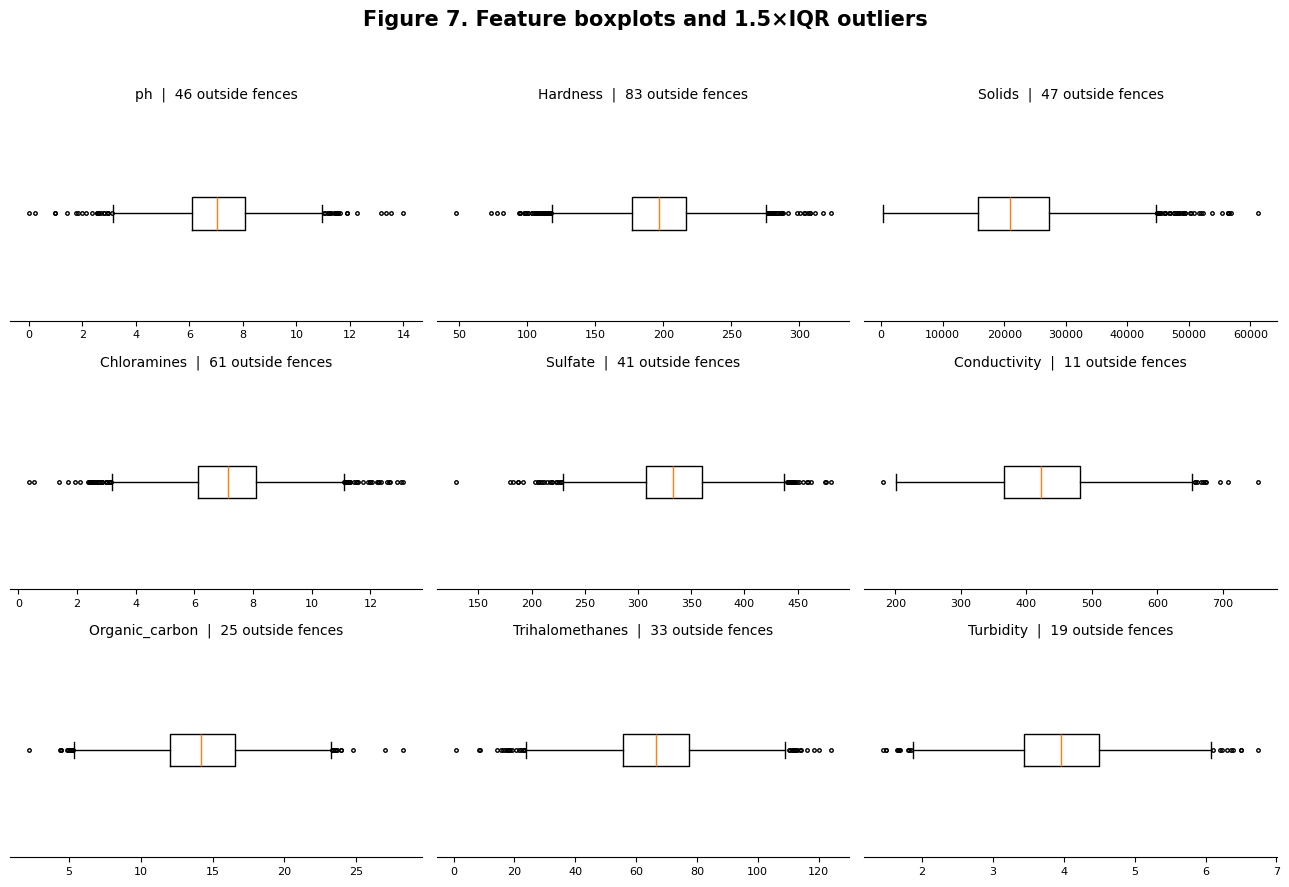

,count,percentage_of_nonmissing
feature,,
ph,46,1.65
Hardness,83,2.53
Solids,47,1.43
Chloramines,61,1.86
Sulfate,41,1.64
Conductivity,11,0.34
Organic_carbon,25,0.76
Trihalomethanes,33,1.06
Turbidity,19,0.58


In [7]:
outlier_rows=[]
fig,axs=plt.subplots(3,3,figsize=(13,9))
for ax,feature in zip(axs.flat,FEATURES):
    vals=raw_df[feature].dropna()
    q1,q3=vals.quantile([.25,.75]);iqr=q3-q1
    low,high=q1-1.5*iqr,q3+1.5*iqr
    count=int(((vals<low)|(vals>high)).sum())
    outlier_rows.append({'feature':feature,'count':count,'percentage_of_nonmissing':count/len(vals)*100,'lower_fence':low,'upper_fence':high})
    ax.boxplot(vals.to_numpy(),vert=False,showfliers=True,flierprops={'markersize':2.5})
    ax.set_title(f'{feature}  |  {count} outside fences',fontsize=10)
    ax.set_yticks([]);ax.tick_params(axis='x',labelsize=8)
    ax.spines[['top','right','left']].set_visible(False)
fig.suptitle('Figure 7. Feature boxplots and 1.5×IQR outliers',fontsize=15,fontweight='bold')
fig.tight_layout(rect=[0,0,1,.95]);fig.savefig(FIGURES_DIR/'figure_07_feature_boxplots.png',dpi=225,bbox_inches='tight')
plt.show()
outlier_table=pd.DataFrame(outlier_rows).set_index('feature')
display(outlier_table[['count','percentage_of_nonmissing']].round(2))
outlier_table.to_csv(OUTPUTS_DIR/'outlier_summary.csv')
for feature in FEATURES:
    f,ax=plt.subplots(figsize=(7.4,3));ax.boxplot(raw_df[feature].dropna(),vert=False,flierprops={'markersize':3})
    ax.set_title('Boxplot — '+feature);ax.set_yticks([]);ax.spines[['top','right','left']].set_visible(False)
    f.tight_layout();f.savefig(INDIVIDUAL_DIR/f'box_{feature}.png',dpi=200,bbox_inches='tight');plt.close(f)

## 7. Pearson correlation — Mohamed Ali (Abu Ali)

Pearson correlations measure **linear association**, not causal importance or model predictive ability. pandas calculates pairwise correlations using available non-null pairs. Near-zero feature–target Pearson coefficients do not establish that prediction is impossible, nor that a non-linear model must necessarily outperform a linear baseline.

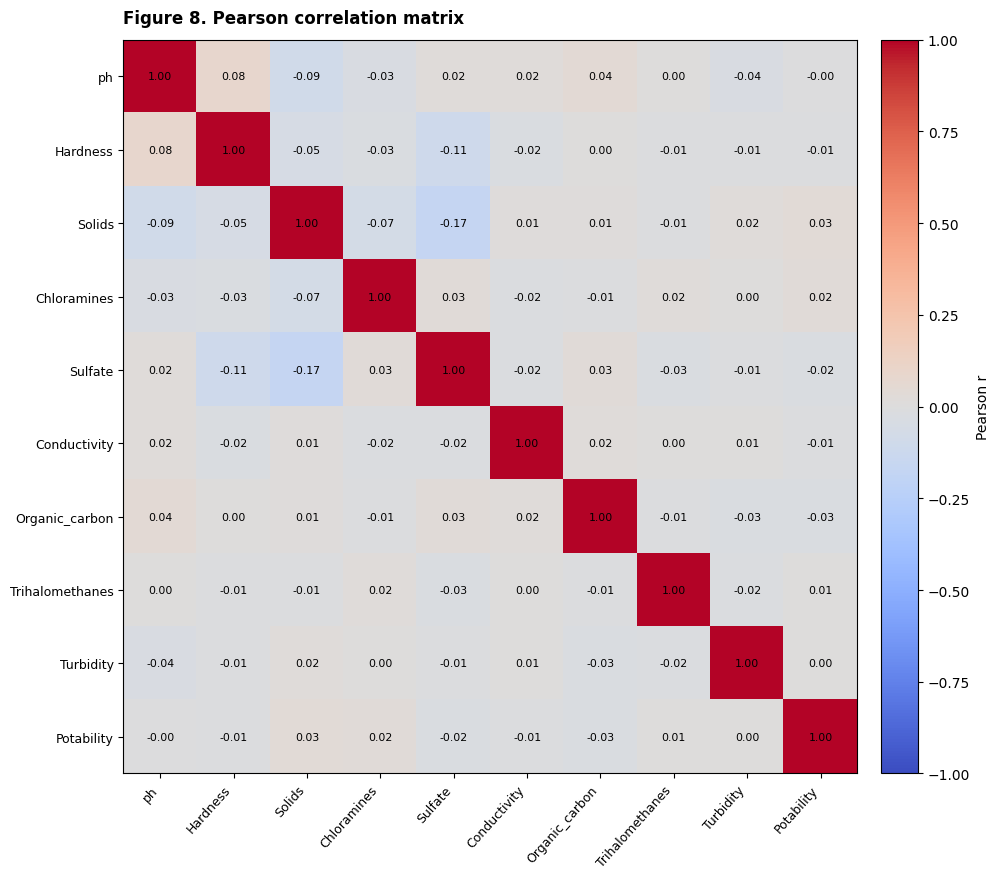

,correlation_with_target
Solids,0.0337
Organic_carbon,-0.0300
Chloramines,0.0238
Sulfate,-0.0236
Hardness,-0.0138
Conductivity,-0.0081
Trihalomethanes,0.0071
ph,-0.0036
Turbidity,0.0016


In [8]:
corr=raw_df[FEATURES+[TARGET]].corr(method='pearson')
fig,ax=plt.subplots(figsize=(10.8,8.9))
im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(np.arange(len(corr.columns)),labels=corr.columns,rotation=48,ha='right',fontsize=9)
ax.set_yticks(np.arange(len(corr.index)),labels=corr.index,fontsize=9)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j,i,f'{corr.iat[i,j]:.2f}',ha='center',va='center',fontsize=7.8)
fig.colorbar(im,ax=ax,fraction=.045,pad=.025,label='Pearson r')
ax.set_title('Figure 8. Pearson correlation matrix',loc='left',fontweight='bold',pad=12)
fig.tight_layout();fig.savefig(FIGURES_DIR/'figure_08_correlation_matrix.png',dpi=230,bbox_inches='tight')
plt.show()
corr.to_csv(OUTPUTS_DIR/'correlation_matrix.csv')
display(corr[TARGET].drop(TARGET).sort_values(key=abs,ascending=False).rename('correlation_with_target').round(4).to_frame())

## 8. Split before fitting preprocessing — Youssef

An 80/20 **stratified** split preserves approximate class proportions. We split the original features and labels **before fitting an imputer or scaler**, using the fixed random seed `42`. Test data remain held out for any later classifier evaluation.

In [9]:
X=raw_df[FEATURES].copy()
y=raw_df[TARGET].copy()
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=TEST_SIZE,random_state=RANDOM_STATE,stratify=y)
assert set(X_train.index).isdisjoint(set(X_test.index))
assert len(X_train)+len(X_test)==len(raw_df)
assert len(X_train)==2620 and len(X_test)==656
split_comparison=pd.DataFrame({
    'full_dataset_pct':y.value_counts(normalize=True).reindex([0,1]).mul(100),
    'train_pct':y_train.value_counts(normalize=True).reindex([0,1]).mul(100),
    'test_pct':y_test.value_counts(normalize=True).reindex([0,1]).mul(100),
    'train_count':y_train.value_counts().reindex([0,1]),
    'test_count':y_test.value_counts().reindex([0,1])
});split_comparison.index.name='class_label'
print(f'Training: {len(X_train):,} samples; Test: {len(X_test):,} samples')
display(split_comparison.round(2))
split_comparison.to_csv(OUTPUTS_DIR/'split_class_balance.csv')

Training: 2,620 samples; Test: 656 samples


,full_dataset_pct,train_pct,test_pct,train_count,test_count
class_label,,,,,
0,60.99,60.99,60.98,1598,400
1,39.01,39.01,39.02,1022,256


## 9. Leakage-safe imputation and scaling — Youssef

Build a scikit-learn `Pipeline` with `SimpleImputer(strategy='median')` followed by `StandardScaler`. The median resists extreme observations; the same choice is used consistently across all numerical input features. **Fit only on `X_train`**, then call `transform` (not `fit_transform`) on `X_test`.

A future estimator must be included inside its own full sklearn Pipeline when conducting cross-validation or hyperparameter tuning. This preprocessing-only notebook is not a fitted classification model.

In [10]:
preprocessing_pipeline=Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler())
])
X_train_processed=preprocessing_pipeline.fit_transform(X_train)
X_test_processed=preprocessing_pipeline.transform(X_test)
X_train_final=pd.DataFrame(X_train_processed,columns=FEATURES,index=X_train.index)
X_test_final=pd.DataFrame(X_test_processed,columns=FEATURES,index=X_test.index)

learned_medians=pd.Series(preprocessing_pipeline.named_steps['imputer'].statistics_,index=FEATURES,name='train_median')
learned_means=pd.Series(preprocessing_pipeline.named_steps['scaler'].mean_,index=FEATURES,name='train_imputed_mean')
learned_scales=pd.Series(preprocessing_pipeline.named_steps['scaler'].scale_,index=FEATURES,name='train_imputed_std')
print('Median values fitted only on the training set for columns containing NaNs:')
display(learned_medians[['ph','Sulfate','Trihalomethanes']].round(4).to_frame())
display(X_train_final.head(4).round(3))

Median values fitted only on the training set for columns containing NaNs:


,train_median
ph,7.0350
Sulfate,333.0735
Trihalomethanes,66.5657


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
2214,0.505,0.371,0.048,-0.792,2.052,0.925,0.565,-0.365,-0.177
1634,-0.709,0.935,-1.016,0.851,1.618,-1.502,-2.169,-1.581,-0.487
2605,0.929,0.981,0.808,-0.586,-0.019,-0.818,0.085,-0.352,0.547
114,-0.228,0.671,-0.002,0.031,-0.019,-0.678,0.775,0.502,-0.092


## 10. Explicit validation and leakage checks — Integration

The assertions below check nonmissing finite transformed data, unchanged train/test row counts and feature order; verify learned medians against original **training-only** statistics; and ensure no index overlap. They do not establish that a later classifier generalizes to other water sources.

In [11]:
assert X_train_final.shape==(len(X_train),len(FEATURES))
assert X_test_final.shape==(len(X_test),len(FEATURES))
assert X_train_final.columns.tolist()==FEATURES==X_test_final.columns.tolist()
assert X_train_final.isna().sum().sum()==0
assert X_test_final.isna().sum().sum()==0
assert np.isfinite(X_train_final.to_numpy()).all() and np.isfinite(X_test_final.to_numpy()).all()
assert set(X_train_final.index).isdisjoint(set(X_test_final.index))
for col in FEATURES:
    assert np.isclose(learned_medians[col],X_train[col].median()),f'Median mismatch in {col}'
assert np.allclose(X_train_final.mean(axis=0).values,0,atol=1e-11)
assert np.allclose(X_train_final.std(axis=0,ddof=0).values,1,atol=1e-11)
print('PASS: No NaNs or infinite features after transformation.')
print('PASS: Split is 2,620 training / 656 testing, stratified and disjoint.')
print('PASS: Median and scaler are fitted on training data only.')
print('PASS: Training features have approximately zero mean and unit population std.')

PASS: No NaNs or infinite features after transformation.
PASS: Split is 2,620 training / 656 testing, stratified and disjoint.
PASS: Median and scaler are fitted on training data only.
PASS: Training features have approximately zero mean and unit population std.


## 11. Save reproducible outputs for research integration

The fitted preprocessing object (no classifier) and four dataset partitions are stored under `outputs/`. Include original row indexes as `source_row_index` when exporting partitions, allowing exact alignment in later experiments. Never fit this saved preprocessing object to test or validation data. Figures and CSV summaries can be included in the paper and website.

In [12]:
joblib.dump(preprocessing_pipeline,OUTPUTS_DIR/'preprocessing_pipeline.joblib')
X_train_final.rename_axis('source_row_index').to_csv(OUTPUTS_DIR/'X_train_processed.csv')
X_test_final.rename_axis('source_row_index').to_csv(OUTPUTS_DIR/'X_test_processed.csv')
y_train.rename_axis('source_row_index').to_csv(OUTPUTS_DIR/'y_train.csv',header=True)
y_test.rename_axis('source_row_index').to_csv(OUTPUTS_DIR/'y_test.csv',header=True)

analysis_summary={
    'dataset_rows':len(raw_df),'dataset_columns':len(raw_df.columns),'feature_columns':FEATURES,
    'target':TARGET,'duplicate_rows':duplicate_rows,
    'complete_rows':int(raw_df.notna().all(axis=1).sum()),
    'missing_counts':{k:int(v) for k,v in missing_count.items()},
    'missing_percentages':{k:round(float(v),4) for k,v in missing_pct.items()},
    'class_counts':{str(k):int(v) for k,v in class_counts.items()},
    'class_percentages':{str(k):round(float(v),4) for k,v in class_pct.items()},
    'outlier_counts_iqr':{k:int(v) for k,v in outlier_table['count'].items()},
    'target_pearson_correlations':{k:round(float(v),5) for k,v in corr[TARGET].drop(TARGET).items()},
    'split':{'train_n':len(X_train),'test_n':len(X_test),'test_size':TEST_SIZE,'stratified':True,'random_state':RANDOM_STATE,
             'train_class_counts':{str(k):int(v) for k,v in y_train.value_counts().items()},
             'test_class_counts':{str(k):int(v) for k,v in y_test.value_counts().items()}},
    'learned_train_medians':{k:round(float(v),6) for k,v in learned_medians.items()},
    'train_missing_after_preprocessing':int(X_train_final.isna().sum().sum()),
    'test_missing_after_preprocessing':int(X_test_final.isna().sum().sum()),
    'note':'Dataset labels are not drinking-water certification. No model trained.'
}
(OUTPUTS_DIR/'analysis_summary.json').write_text(json.dumps(analysis_summary,indent=2),encoding='utf-8')
print('Saved all figures, tables, partitions and preprocessing_pipeline.joblib.')
print('Notebook completed successfully. No ML classifier or potability guarantee is provided.')

Saved all figures, tables, partitions and preprocessing_pipeline.joblib.
Notebook completed successfully. No ML classifier or potability guarantee is provided.


## 12. Interpretation and limits

- **Missingness:** only `ph`, `Sulfate`, and `Trihalomethanes` have NaNs. Missingness mechanism is unknown; median replacement is a pragmatic baseline, not proof of unbiased data recovery.
- **Imbalance:** class 0 is about 61% and class 1 about 39%; use per-class metrics and stratification during downstream model evaluation.
- **Distributions/outliers:** `Solids` is right-skewed; 1.5×IQR counts describe unusual observations, not automatic data-entry errors. Original records remain intact.
- **Correlation:** marginal Pearson correlations with the label are weak. They do not resolve whether supervised modeling will succeed.
- **Feature compatibility:** the public dataset has nine model inputs; a basic pH/TDS/turbidity/temperature kit does not directly supply all nine. Live inference requires matching and independently validated input features; do not fabricate unavailable chemistry values.
- **Next phase (out of academic scope):** model selection, cross-validation within training folds and final held-out evaluation are separate future tasks.

**Primary source:** Kaggle Water Quality and Potability (adityakadiwal/water-potability). **Project methodology:** October 2026 proposal and supplied group notebooks; source/label provenance requires independent verification for operational applications.